In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, mutual_info_regression

In [2]:
# Load sample dataset
#data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data2/Data.csv')

In [3]:
Data = Data.iloc[:, 1:]

In [4]:
Data

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,14.52,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,14.52,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,25.71,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,25.71,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,115.84,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,91.25,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,91.25,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,85.24,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [5]:
# create new column "Labels" based on "FPS"
Data["Labels"] = Data["FPS"].apply(lambda x: 0 if x >= 60 else 1)

In [6]:
Data

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,...,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll,Labels
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,0.00,...,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71,0
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,14.52,...,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73,0
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,14.52,...,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75,0
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,25.71,...,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85,0
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,25.71,...,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,115.84,...,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87,1
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,91.25,...,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15,1
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,91.25,...,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37,1
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,85.24,...,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80,1


In [7]:
Data.shape

(10332, 21)

In [8]:
# Separate the features and the target variable
X = Data.drop('Labels', axis=1)

In [9]:
X

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,14.52,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,14.52,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,25.71,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,25.71,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,115.84,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,91.25,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,91.25,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,85.24,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [10]:
y = Data['Labels']

In [11]:
y

0        0
1        0
2        0
3        0
4        0
        ..
10327    1
10328    1
10329    1
10330    1
10331    1
Name: Labels, Length: 10332, dtype: int64

In [12]:
# Use SelectKBest with mutual_info_regression as the scoring function
k = 5
skb = SelectKBest(mutual_info_regression, k=k)
X_skb = skb.fit_transform(X, y)

In [13]:
# Print the selected features
selected_features = X.columns[skb.get_support()]
print("Selected_Features:",  selected_features)

Selected_Features: Index(['FPS', 'Frame Duration (ms)', 'Max Frame Duration (ms)',
       'Avg Frame Duration (ms)', 'MotionToPhotonLatency'],
      dtype='object')


In [14]:
# Calculate feature importances using Mutual Information from SelectKBest
feature_importances = skb.scores_[skb.get_support()]

In [15]:
# Sort the features and their importances from most to least important

sorted_indices = np.argsort(feature_importances)[::-1]
sorted_features  = selected_features[sorted_indices]
sorted_importance = feature_importances[sorted_indices]

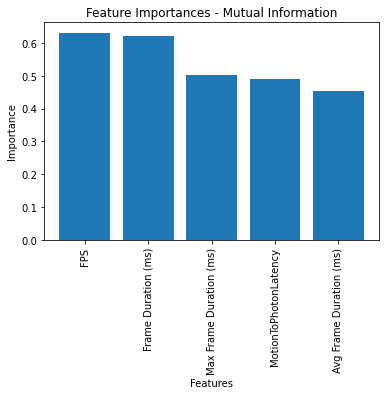

In [16]:
# Plot a bar chart of the sorted feature importances
plt.bar(sorted_features, sorted_importance)
plt.title("Feature Importances - Mutual Information")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=90)
plt.show()

In [17]:
# Get all feature importances
all_feature_importances = skb.scores_
all_feature_importances_df = pd.DataFrame({"Feature": X.columns, "Importance": all_feature_importances})

In [18]:
# Print mutual information value for each feature
print("All Feature Importances:")
print(all_feature_importances_df)

All Feature Importances:
                    Feature  Importance
0                       FPS    0.631569
1       Frame Duration (ms)    0.622059
2   Min Frame Duration (ms)    0.429218
3   Max Frame Duration (ms)    0.502592
4   Avg Frame Duration (ms)    0.453397
5              Std Dev (ms)    0.425647
6         Entropy Framerate    0.162289
7     MotionToPhotonLatency    0.489333
8             minMtpLatency    0.427931
9             maxMtpLatency    0.424015
10            avgMtpLatency    0.431452
11        StdDev mtpLatency    0.314796
12               mtpEntropy    0.063688
13        currentRotation.x    0.077792
14        currentRotation.y    0.171400
15        currentRotation.z    0.063566
16        currentRotation.w    0.052606
17                    pitch    0.063614
18                      yaw    0.164647
19                     roll    0.020927


In [19]:
# Sort the features and their importances from most to least important
sorted_indices = np.argsort(all_feature_importances)[::-1]
sorted_features = X.columns[sorted_indices]
sorted_importance = all_feature_importances[sorted_indices]

In [26]:
# Create a DataFrame with the sorted feature importances
sorted_importances_df = pd.DataFrame({"Feature": sorted_features, "Importance": sorted_importance})

In [27]:
sorted_importances_df

,Feature,Importance
0,FPS,0.631569
1,Frame Duration (ms),0.622059
2,Max Frame Duration (ms),0.502592
3,MotionToPhotonLatency,0.489333
4,Avg Frame Duration (ms),0.453397
5,avgMtpLatency,0.431452
6,Min Frame Duration (ms),0.429218
7,minMtpLatency,0.427931
8,Std Dev (ms),0.425647
9,maxMtpLatency,0.424015


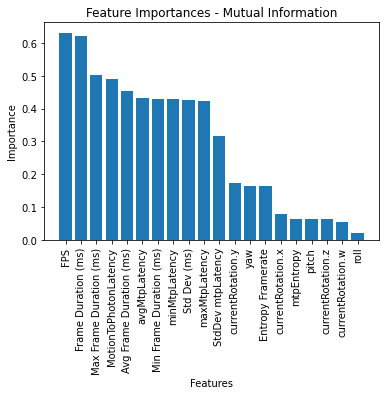

In [20]:
# Plot a bar chart of the sorted feature importances
plt.bar(sorted_features, sorted_importance)
plt.title("Feature Importances - Mutual Information")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=90)
plt.show()